# Gabarito — Triângulos Quaisquer

Este notebook traz a resolução comentada dos exercícios de [`0417a_triangulos_quaisquer.ipynb`](0417a_triangulos_quaisquer.ipynb).

⚠️ **Antes de olhar aqui:** tente resolver os exercícios sozinho no notebook original e use as células de verificação (`assert`) para conferir sua resposta. Volte a este gabarito só depois de tentar — ou se travar de verdade em algum passo.

In [1]:
# Imports e ferramentas necessários para os exercícios abaixo (reconstruídos do notebook principal)
import math
from fractions import Fraction

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Arc, Circle, Polygon, Rectangle, Wedge

# Paleta de cores Nord
NORD_FUNDO = "#2E3440"
NORD_PAINEL = "#3B4252"
NORD_LINHA = "#4C566A"
NORD_TEXTO = "#ECEFF4"
NORD_TEXTO_SEC = "#D8DEE9"
COR_PONTO = "#88C0D0"
COR_DESTAQUE = "#A3BE8C"
COR_ALERTA = "#BF616A"
COR_SECUNDARIA = "#81A1C1"
COR_EXTRA = "#B48EAD"
COR_AVISO = "#EBCB8B"


def estilizar_eixo(ax) -> None:
    """Aplica o estilo Nord padrão a um eixo do matplotlib."""
    ax.set_facecolor(NORD_FUNDO)
    ax.tick_params(colors=NORD_TEXTO_SEC)
    for spine in ax.spines.values():
        spine.set_color(NORD_LINHA)
    ax.grid(color=NORD_LINHA, linewidth=0.5, alpha=0.5)


# Ferramentas do notebook principal e dos anteriores (0401a, 0402a, 0407a, 0410a, 0412a, 0415a e 0416a)

def preparar_eixo(ax, pontos, margem: float = 0.8) -> None:
    """Deixa o eixo pronto para desenhos de geometria (estilo Nord, sem grade, sem números,
    escala igual) e enquadra todos os `pontos` com uma margem em volta."""
    estilizar_eixo(ax)
    ax.grid(False)
    xs = [p[0] for p in pontos]
    ys = [p[1] for p in pontos]
    ax.set_xlim(min(xs) - margem, max(xs) + margem)
    ax.set_ylim(min(ys) - margem, max(ys) + margem)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])


def direcao(angulo_graus: float) -> np.ndarray:
    """Vetor de tamanho 1 apontando na direção dada, em graus, a partir da horizontal (sentido anti-horário).

    (cos e sin vêm da Trigonometria, módulo 05; aqui só servem para apontar na direção certa.)
    """
    rad = math.radians(angulo_graus)
    return np.array([math.cos(rad), math.sin(rad)])


def direcao_de(origem, destino) -> float:
    """Direção, em graus, em que `destino` está quando visto de `origem`."""
    return math.degrees(math.atan2(destino[1] - origem[1], destino[0] - origem[0]))


def medir_angulo(vertice, P, Q) -> float:
    """Transferidor digital: medida, em graus, do ângulo com vértice em `vertice`
    formado pelas semirretas que passam por P e por Q (resultado entre 0° e 180°)."""
    u = np.subtract(P, vertice)
    v = np.subtract(Q, vertice)
    cosseno = np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))
    return math.degrees(math.acos(np.clip(cosseno, -1, 1)))


def cruzamento(P, inclinacao_1: float, Q, inclinacao_2: float):
    """Ponto em que a reta que passa por P (com a inclinação `inclinacao_1`, em graus) cruza a reta
    que passa por Q (com a inclinação `inclinacao_2`). Devolve None se as duas retas tiverem a mesma
    direção, porque aí elas não se cruzam num ponto só.

    Por trás, é um sistema linear 2×2 (módulo 03): P + t·u = Q + k·v, com incógnitas t e k.
    """
    matriz = np.column_stack([direcao(inclinacao_1), -direcao(inclinacao_2)])
    if abs(np.linalg.det(matriz)) < 1e-12:
        return None
    t, _ = np.linalg.solve(matriz, np.subtract(Q, P))
    return np.array(P, dtype=float) + t * direcao(inclinacao_1)


def ponto_medio(P, Q) -> np.ndarray:
    """Ponto médio do segmento PQ: a média das coordenadas (0402a)."""
    return (np.asarray(P, dtype=float) + np.asarray(Q, dtype=float)) / 2


def iguais(x: float, y: float) -> bool:
    """Compara duas medidas com uma tolerância pequena (as contas com float têm arredondamentos)."""
    return math.isclose(x, y, rel_tol=1e-9, abs_tol=1e-6)


def desenhar_ponto(ax, p, nome: str = "", cor: str = COR_AVISO, deslocamento=(0.12, 0.15),
                   tamanho_fonte: int = 13) -> None:
    """Desenha um ponto com seu nome (letra maiúscula) ao lado."""
    ax.plot(*p, "o", color=cor, markersize=7, zorder=6)
    if nome:
        ax.text(p[0] + deslocamento[0], p[1] + deslocamento[1], nome, color=NORD_TEXTO, fontsize=tamanho_fonte,
                fontweight="bold", zorder=7)


def desenhar_segmento(ax, P, Q, cor: str = NORD_TEXTO, largura: float = 3.0, estilo: str = "-",
                      alpha: float = 1.0, zorder: int = 5) -> None:
    """Desenha o segmento PQ (só o pedaço entre P e Q)."""
    ax.plot(*zip(P, Q), color=cor, lw=largura, linestyle=estilo, alpha=alpha, zorder=zorder,
            solid_capstyle="round")


def desenhar_setor(ax, vertice, inicio: float, abertura: float, raio: float = 0.5, cor: str = COR_PONTO,
                   rotulo: str | None = None, marcar_reto: bool = True, raio_rotulo: float | None = None,
                   tamanho_fonte: int = 11) -> None:
    """Pinta o ângulo com vértice em `vertice` que começa na direção `inicio` e gira `abertura`
    graus no sentido anti-horário. O ângulo reto ganha o quadradinho no lugar do arco."""
    v = np.array(vertice, dtype=float)
    if marcar_reto and math.isclose(abertura, 90, abs_tol=1e-6):
        lado = 0.6 * raio
        canto = [v, v + lado * direcao(inicio), v + lado * (direcao(inicio) + direcao(inicio + 90)),
                 v + lado * direcao(inicio + 90)]
        ax.add_patch(Polygon(canto, closed=True, facecolor=cor, alpha=0.35, edgecolor=cor, lw=2))
    else:
        ax.add_patch(Wedge(v, raio, inicio, inicio + abertura, facecolor=cor, alpha=0.3, edgecolor="none"))
        ax.add_patch(Arc(v, 2 * raio, 2 * raio, theta1=inicio, theta2=inicio + abertura, color=cor, lw=2))
    if rotulo:
        distancia_rotulo = 1.6 * raio if raio_rotulo is None else raio_rotulo
        posicao = v + distancia_rotulo * direcao(inicio + abertura / 2)
        ax.text(*posicao, rotulo, color=cor, fontsize=tamanho_fonte, ha="center", va="center", fontweight="bold")


def desenhar_arco(ax, vertice, p, q, **opcoes) -> None:
    """Marca o ângulo de vértice `vertice` formado pelas semirretas que passam por p e por q
    (sempre a abertura menor, entre 0° e 180°). Aceita as mesmas opções de `desenhar_setor`."""
    inicio = direcao_de(vertice, p) % 360
    abertura = (direcao_de(vertice, q) - inicio) % 360
    if abertura > 180:
        inicio, abertura = direcao_de(vertice, q) % 360, 360 - abertura
    desenhar_setor(ax, vertice, inicio, abertura, **opcoes)


def rotular_fora(ax, P, texto: str, centro, cor: str = NORD_TEXTO, distancia: float = 0.35,
                 tamanho: int = 12) -> None:
    """Escreve `texto` perto do ponto P, afastado do `centro` (para não ficar em cima da figura)."""
    P = np.asarray(P, dtype=float)
    afastar = P - np.asarray(centro, dtype=float)
    afastar = afastar / np.linalg.norm(afastar) if np.linalg.norm(afastar) > 0 else np.array([0.0, 1.0])
    ax.text(*(P + distancia * afastar), texto, color=cor, fontsize=tamanho, fontweight="bold",
            ha="center", va="center", zorder=7)


def rotular_segmento(ax, P, Q, texto: str, cor: str = NORD_TEXTO, distancia: float = 0.35, longe_de=None,
                     tamanho: int = 11) -> None:
    """Escreve `texto` ao lado do meio do segmento PQ, afastado `distancia` na direção perpendicular a ele.
    Se `longe_de` for um ponto, o texto vai para o lado do segmento oposto a esse ponto."""
    P, Q = np.asarray(P, dtype=float), np.asarray(Q, dtype=float)
    u = (Q - P) / np.linalg.norm(Q - P)
    normal = np.array([-u[1], u[0]])
    meio = (P + Q) / 2
    if longe_de is not None and np.dot(meio - np.asarray(longe_de, dtype=float), normal) < 0:
        normal = -normal
    ax.text(*(meio + distancia * normal), texto, color=cor, fontsize=tamanho, fontweight="bold",
            ha="center", va="center", zorder=7)


def escrever_checklist(ax, itens, titulo: str = "") -> None:
    """Painel de texto com uma linha por item (texto, ok): ✓ verde quando vale, ✗ vermelho quando não (0410a)."""
    ax.set_facecolor(NORD_FUNDO)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    if titulo:
        ax.text(0.0, 0.97, titulo, color=NORD_TEXTO, fontsize=12, fontweight="bold", va="top")
    passo = min(0.13, 0.85 / max(len(itens), 1))
    for k, (texto, ok) in enumerate(itens):
        ax.text(0.0, 0.84 - k * passo, f"{'✓' if ok else '✗'}  {texto}", color=COR_DESTAQUE if ok else COR_ALERTA,
                fontsize=11, va="top")


def desenhar_circunferencia(ax, O, r: float, cor: str = COR_PONTO, estilo: str = "-",
                            largura: float = 2.5, preencher: bool = False, opacidade: float = 0.15) -> None:
    """Desenha a circunferência de centro O e raio r (a linha). Com `preencher=True`, pinta também a
    região interna: o círculo (0412a)."""
    O = tuple(np.asarray(O, dtype=float))
    if preencher:
        ax.add_patch(Circle(O, r, facecolor=cor, alpha=opacidade, edgecolor="none", zorder=1))
    ax.add_patch(Circle(O, r, fill=False, edgecolor=cor, lw=largura, linestyle=estilo, zorder=3))


def lados(t) -> tuple[float, float, float]:
    """Medidas (a, b, c) dos lados do triângulo t = (A, B, C), na convenção de 0404a: a = BC é oposto a A,
    b = CA é oposto a B e c = AB é oposto a C."""
    A, B, C = t
    return math.dist(B, C), math.dist(C, A), math.dist(A, B)


def angulos(t) -> tuple[float, float, float]:
    """Medidas, em graus, dos ângulos internos (Â, B̂, Ĉ) do triângulo t = (A, B, C)."""
    A, B, C = t
    return medir_angulo(A, B, C), medir_angulo(B, C, A), medir_angulo(C, A, B)


def cruzamento_circunferencias(P, r1: float, Q, r2: float):
    """Um ponto comum às circunferências λ(P, r1) e λ(Q, r2): o que fica à ESQUERDA de quem anda de P para Q
    (0415a). Devolve None se as duas circunferências não se cruzam."""
    P, Q = np.asarray(P, dtype=float), np.asarray(Q, dtype=float)
    d = math.dist(P, Q)
    if not abs(r1 - r2) < d < r1 + r2:
        return None
    x = (d**2 + r1**2 - r2**2) / (2 * d)
    y = math.sqrt(r1**2 - x**2)
    u = (Q - P) / d
    return P + x * u + y * np.array([-u[1], u[0]])


def pe_da_altura(vertice, P, Q) -> np.ndarray:
    """Pé da altura traçada de `vertice` até a reta PQ: a projeção ortogonal do vértice sobre essa reta (0407a e
    0410a). Em coordenadas, H = P + ((V − P)·(Q − P) / |Q − P|²)·(Q − P)."""
    V, P, Q = (np.asarray(X, dtype=float) for X in (vertice, P, Q))
    u = Q - P
    return P + np.dot(V - P, u) / np.dot(u, u) * u


def distancia_ponto_reta(X, P, Q) -> float:
    """Distância do ponto X à reta PQ: a medida de X até o pé da perpendicular (0407a)."""
    return math.dist(X, pe_da_altura(X, P, Q))


def baricentro(A, B, C) -> np.ndarray:
    """Baricentro G: a média das coordenadas dos três vértices (0410a)."""
    return (np.asarray(A, dtype=float) + np.asarray(B, dtype=float) + np.asarray(C, dtype=float)) / 3


def incentro(A, B, C) -> np.ndarray:
    """Incentro I: a média dos vértices ponderada pelos lados opostos, I = (a·A + b·B + c·C) / (a + b + c) (0410a)."""
    a, b, c = lados([A, B, C])
    A, B, C = (np.asarray(X, dtype=float) for X in (A, B, C))
    return (a * A + b * B + c * C) / (a + b + c)


def circuncentro(A, B, C) -> np.ndarray:
    """Circuncentro: o cruzamento das mediatrizes de AB e de BC, as perpendiculares aos lados pelos pontos
    médios (0407a e 0410a)."""
    return cruzamento(ponto_medio(A, B), direcao_de(A, B) + 90, ponto_medio(B, C), direcao_de(B, C) + 90)


def classifica_por_lados(x: float, y: float, z: float) -> str:
    """Classifica o triângulo de lados x, y, z (em qualquer ordem) quanto aos ângulos, só pelos lados:
    'acutângulo', 'retângulo', 'obtusângulo' ou 'não forma triângulo' (0416a)."""
    a, b, c = sorted((x, y, z), reverse=True)  # a é o MAIOR lado
    if c <= 0 or a >= b + c:  # desigualdade triangular (0404a)
        return "não forma triângulo"
    if math.isclose(a**2, b**2 + c**2, rel_tol=1e-9, abs_tol=1e-12):
        return "retângulo"
    return "acutângulo" if a**2 < b**2 + c**2 else "obtusângulo"


# Ferramentas novas deste notebook
# Notação fixa: a = BC, b = CA, c = AB (cada lado na cor do notebook 0416a); h = altura (laranja); nas projeções,
# m = BH (roxo, a cor de c) e n = HC (verde, a cor de b). As cevianas e as circunferências também têm cor fixa.
COR_LADO_A = COR_AVISO  # a: amarelo
COR_LADO_B = COR_DESTAQUE  # b e a projeção n: verde
COR_LADO_C = COR_EXTRA  # c e a projeção m: roxo
COR_ALTURA = "#D08770"  # alturas: laranja
COR_MEDIANA = COR_PONTO  # medianas: azul-claro
COR_BISSETRIZ = COR_ALERTA  # bissetrizes: vermelho
COR_CIRCUNSCRITA = COR_SECUNDARIA  # circunferência circunscrita: azul
COR_INSCRITA = "#8FBCBB"  # circunferência inscrita: verde-água
COR_PARTE_M = "#5E81AC"  # Stewart: a parte BD = m (azul-escuro)
COR_PARTE_N = "#8FBCBB"  # Stewart: a parte DC = n (verde-água)
COR_TRIANGULO = COR_PONTO  # preenchimento dos triângulos


def desenhar_triangulo(ax, A, B, C, valores: bool = True, tamanho: int = 12, preencher: bool = True,
                       rotular_a: bool = True) -> None:
    """Figura padrão do triângulo ABC: a (amarelo), b (verde) e c (roxo), com os nomes dos vértices."""
    A, B, C = (np.asarray(X, dtype=float) for X in (A, B, C))
    a, b, c = lados((A, B, C))
    centro, escala = (A + B + C) / 3, max(a, b, c)
    if preencher:
        ax.add_patch(Polygon([A, B, C], closed=True, facecolor=COR_TRIANGULO, alpha=0.12, edgecolor="none",
                             zorder=1))
    for P, Q, cor, nome, valor in ((B, C, COR_LADO_A, "a", a), (C, A, COR_LADO_B, "b", b), (A, B, COR_LADO_C, "c", c)):
        desenhar_segmento(ax, P, Q, cor=cor, largura=3.5)
        if nome != "a" or rotular_a:
            rotular_segmento(ax, P, Q, f"{nome} = {valor:.4g}" if valores else nome, cor=cor,
                             distancia=0.06 * escala, longe_de=centro, tamanho=tamanho)
    for X, nome in ((A, "A"), (B, "B"), (C, "C")):
        desenhar_ponto(ax, X, cor=NORD_TEXTO)
        rotular_fora(ax, X, nome, centro, distancia=0.06 * escala, tamanho=tamanho + 1)


def desenhar_projecao(ax, A, B, C, valores: bool = True, faixa: bool = False, tamanho: int = 12) -> list:
    """Triângulo ABC com o lado BC DEITADO no eixo x (B à esquerda de C), a altura AH e as projeções
    m = BH (roxo) e n = HC (verde), com sinal: n < 0 quando H cai depois de C. Com `faixa=True`, desenha
    abaixo de BC as duas faixas a × |n|, cuja área total 2·a·|n| é o que falta (ou sobra) em c² perto de
    a² + b². Devolve pontos que enquadram o desenho (para `preparar_eixo`)."""
    A, B, C = (np.asarray(X, dtype=float) for X in (A, B, C))
    a, b, c = lados((A, B, C))
    escala = max(a, b, c)
    H = pe_da_altura(A, B, C)
    n, m = C[0] - H[0], H[0] - B[0]  # com sinal (BC está sobre o eixo x)
    desenhar_triangulo(ax, A, B, C, valores=valores, tamanho=tamanho, rotular_a=False)
    if H[0] > C[0] + 1e-9:
        desenhar_segmento(ax, C, H, cor=NORD_TEXTO_SEC, largura=1.5, estilo=":")
    if H[0] < B[0] - 1e-9:
        desenhar_segmento(ax, H, B, cor=NORD_TEXTO_SEC, largura=1.5, estilo=":")
    desenhar_segmento(ax, A, H, cor=COR_ALTURA, largura=2.5, estilo="--")
    if abs(n) > 0.04 * escala and abs(m) > 0.04 * escala:
        desenhar_setor(ax, H, 0 if n > 0 else 90, 90, raio=0.07 * escala, cor=COR_ALTURA)
    lado_h = -1 if n >= 0 else 1  # o rótulo de h vai para o lado oposto ao lado b (que sai de C)
    ax.text(H[0] + 0.015 * escala * lado_h, A[1] / 2, f"h = {A[1]:.4g}" if valores else "h",
            color=COR_ALTURA, fontsize=tamanho, fontweight="bold", ha="left" if lado_h > 0 else "right", va="center")
    desenhar_ponto(ax, H, cor=COR_ALTURA)
    ax.text(H[0], H[1] + 0.05 * escala, "H", color=NORD_TEXTO, fontsize=tamanho + 1, fontweight="bold",
            ha="center", va="bottom", zorder=7)
    # "Réguas" das projeções, em duas alturas para não se sobreporem
    for P, Q, y, cor, nome, valor in ((B, H, -0.07, COR_LADO_C, "m", m), (H, C, -0.14, COR_LADO_B, "n", n)):
        if math.dist(P, Q) < 1e-9:
            continue
        P2, Q2 = P + (0, y * escala), Q + (0, y * escala)
        desenhar_segmento(ax, P2, Q2, cor=cor, largura=3)
        for X in (P2, Q2):
            desenhar_segmento(ax, X + (0, 0.02 * escala), X - (0, 0.02 * escala), cor=cor, largura=1.5)
        ax.text((P2[0] + Q2[0]) / 2, P2[1] - 0.012 * escala, f"{nome} = {valor:.3g}" if valores else nome,
                color=cor, fontsize=tamanho - 1, fontweight="bold", ha="center", va="top")
    y_a = -0.25 * escala
    ax.text((B[0] + C[0]) / 2, y_a, f"a = {a:.4g}" if valores else "a", color=COR_LADO_A, fontsize=tamanho,
            fontweight="bold", ha="center", va="center")
    pontos = [A, B, C, H, np.array([B[0], y_a - 0.03 * escala])]
    if faixa and abs(n) > 1e-9:
        cor = COR_AVISO if n > 0 else COR_ALERTA
        topo = y_a - 0.06 * escala
        for k in range(2):
            ax.add_patch(Rectangle((B[0], topo - (k + 1) * abs(n)), a, abs(n), facecolor=cor, alpha=0.3,
                                   edgecolor=cor, lw=1.5))
            ax.text(B[0] + a / 2, topo - (k + 0.5) * abs(n), f"a·|n| = {a * abs(n):.3g}", color=cor,
                    fontsize=tamanho - 1, fontweight="bold", ha="center", va="center")
        pontos.append(np.array([B[0], topo - 2 * abs(n)]))
    return pontos


def existe_triangulo(a: float, b: float, c: float) -> bool:
    """Desigualdade triangular (0404a): três medidas positivas formam triângulo se cada uma é menor que a soma
    das outras duas."""
    return a > 0 and b > 0 and c > 0 and a < b + c and b < a + c and c < a + b


def projecao_lado(a: float, b: float, c: float) -> float:
    """Projeção n = HC do lado b sobre o lado a, COM SINAL: n = (a² + b² − c²)/(2a). Positiva se o ângulo C é
    agudo, zero se é reto e negativa se é obtuso (nesse caso H cai depois de C e HC = |n|)."""
    return (a**2 + b**2 - c**2) / (2 * a)


def altura_por_lados(a: float, b: float, c: float) -> float:
    """Altura h_a, relativa ao lado a, pelos três lados: h_a = √(b² − n²) (Pitágoras no triângulo AHC)."""
    if not existe_triangulo(a, b, c):
        raise ValueError(f"as medidas {a}, {b}, {c} não formam triângulo (desigualdade triangular)")
    n = projecao_lado(a, b, c)
    return math.sqrt(b**2 - n**2)


def triangulo_por_lados(a: float, b: float, c: float):
    """Triângulo (A, B, C) com BC = a deitado no eixo x: B = (0, 0), C = (a, 0) e A = (m, h_a), com m = a − n.
    Devolve None se as medidas não formam triângulo."""
    if not existe_triangulo(a, b, c):
        return None
    n = projecao_lado(a, b, c)
    return np.array([a - n, altura_por_lados(a, b, c)]), np.array([0.0, 0.0]), np.array([float(a), 0.0])


def semiperimetro(a: float, b: float, c: float) -> float:
    """Semiperímetro p = (a + b + c)/2."""
    return (a + b + c) / 2


def area_herao(a: float, b: float, c: float) -> float:
    """Área do triângulo de lados a, b, c pela fórmula de Herão: S = √(p(p − a)(p − b)(p − c))."""
    if not existe_triangulo(a, b, c):
        raise ValueError(f"as medidas {a}, {b}, {c} não formam triângulo (desigualdade triangular)")
    p = semiperimetro(a, b, c)
    return math.sqrt(p * (p - a) * (p - b) * (p - c))


def segmentos_tangentes(a: float, b: float, c: float) -> tuple[float, float, float]:
    """Segmentos tangentes da circunferência inscrita traçados de A, B e C: (p − a, p − b, p − c)."""
    p = semiperimetro(a, b, c)
    return p - a, p - b, p - c


def raio_inscrito(a: float, b: float, c: float) -> float:
    """Raio da circunferência inscrita: r = S/p."""
    return area_herao(a, b, c) / semiperimetro(a, b, c)


def raio_circunscrito(a: float, b: float, c: float) -> float:
    """Raio da circunferência circunscrita: R = abc/(4S)."""
    return a * b * c / (4 * area_herao(a, b, c))


def mediana(a: float, b: float, c: float, qual: str = "a") -> float:
    """Comprimento da mediana relativa ao lado `qual` ("a", "b" ou "c"): m_a = ½·√(2b² + 2c² − a²)."""
    oposto, outros = {"a": (a, (b, c)), "b": (b, (a, c)), "c": (c, (a, b))}[qual]
    return math.sqrt(2 * outros[0] ** 2 + 2 * outros[1] ** 2 - oposto**2) / 2


def medianas(a: float, b: float, c: float) -> tuple[float, float, float]:
    """As três medianas (m_a, m_b, m_c)."""
    return mediana(a, b, c, "a"), mediana(a, b, c, "b"), mediana(a, b, c, "c")


def stewart(a: float, b: float, c: float, m: float) -> float:
    """Comprimento d = AD da ceviana que chega ao ponto D de BC com BD = m (0 ≤ m ≤ a), pelo teorema de Stewart:
    b²·m + c²·n = a·(d² + m·n), com n = a − m."""
    n = a - m
    return math.sqrt((b**2 * m + c**2 * n) / a - m * n)


def pe_da_bissetriz(a: float, b: float, c: float) -> tuple[float, float]:
    """Partes (m, n) = (BD, DC) em que a bissetriz de A divide o lado a: BD/DC = c/b (0414a)."""
    return a * c / (b + c), a * b / (b + c)


def bissetriz(a: float, b: float, c: float, qual: str = "a") -> float:
    """Comprimento da bissetriz interna traçada até o lado `qual`: t_a = 2·√(b·c·p·(p − a)) / (b + c)."""
    oposto, (x, y) = {"a": (a, (b, c)), "b": (b, (a, c)), "c": (c, (a, b))}[qual]
    p = semiperimetro(a, b, c)
    return 2 * math.sqrt(x * y * p * (p - oposto)) / (x + y)


def ficha_triangulo(a: float, b: float, c: float) -> dict:
    """Ficha técnica do triângulo de lados a, b, c: todos os elementos calculados só pelos lados."""
    if not existe_triangulo(a, b, c):
        return {"existe": False, "classificação": "não forma triângulo"}
    S = area_herao(a, b, c)
    return {
        "existe": True,
        "classificação": classifica_por_lados(a, b, c),
        "perímetro": a + b + c,
        "p": semiperimetro(a, b, c),
        "S": S,
        "r": raio_inscrito(a, b, c),
        "R": raio_circunscrito(a, b, c),
        "h_a": 2 * S / a, "h_b": 2 * S / b, "h_c": 2 * S / c,
        "m_a": mediana(a, b, c, "a"), "m_b": mediana(a, b, c, "b"), "m_c": mediana(a, b, c, "c"),
        "t_a": bissetriz(a, b, c, "a"), "t_b": bissetriz(a, b, c, "b"), "t_c": bissetriz(a, b, c, "c"),
        "tangentes": segmentos_tangentes(a, b, c),
    }


def pe_bissetriz_medido(V, P, Q) -> np.ndarray:
    """Pé da bissetriz do ângulo de vértice V no lado PQ, por coordenadas: a reta que sai de V na direção da soma
    dos vetores unitários VP e VQ cruza a reta PQ."""
    V, P, Q = (np.asarray(X, dtype=float) for X in (V, P, Q))
    u = (P - V) / math.dist(V, P) + (Q - V) / math.dist(V, Q)
    return cruzamento(V, direcao_de(V, V + u), P, direcao_de(P, Q))


def medir_ficha(A, B, C) -> dict:
    """Os mesmos elementos de `ficha_triangulo`, medidos DIRETAMENTE nas coordenadas (sem as fórmulas)."""
    O, I = circuncentro(A, B, C), incentro(A, B, C)
    a, b, c = lados((A, B, C))
    return {
        "perímetro": a + b + c,
        "S": a * distancia_ponto_reta(A, B, C) / 2,
        "r": distancia_ponto_reta(I, B, C),
        "R": math.dist(O, A),
        "h_a": distancia_ponto_reta(A, B, C), "h_b": distancia_ponto_reta(B, C, A),
        "h_c": distancia_ponto_reta(C, A, B),
        "m_a": math.dist(A, ponto_medio(B, C)), "m_b": math.dist(B, ponto_medio(C, A)),
        "m_c": math.dist(C, ponto_medio(A, B)),
        "t_a": math.dist(A, pe_bissetriz_medido(A, B, C)), "t_b": math.dist(B, pe_bissetriz_medido(B, C, A)),
        "t_c": math.dist(C, pe_bissetriz_medido(C, A, B)),
        "tangentes": (math.dist(A, pe_da_altura(I, A, B)), math.dist(B, pe_da_altura(I, B, C)),
                      math.dist(C, pe_da_altura(I, C, A))),
    }

## Básico

**Exercício 1.** Classificação pelos lados, projeção e altura.

In [2]:
# (a) Ordena-se para achar o maior lado, testa-se a desigualdade triangular e compara-se ℓ² com a soma
trios_ex1 = [(6, 7, 8), (9, 12, 15), (5, 6, 9), (2, 3, 6), (7, 8, 10)]
classificacoes_ex1a = [classifica_por_lados(*t) for t in trios_ex1]

# (b) Projeção com sinal: n = (a² + b² − c²)/(2a) = (441 + 289 − 100)/42 = 630/42 = 15
n_ex1b = (21**2 + 17**2 - 10**2) / (2 * 21)
m_ex1b = 21 - n_ex1b  # m = BH = a − n = 6

# (c) Pitágoras em AHC: h² = b² − n² = 289 − 225 = 64
h_ex1c = math.sqrt(17**2 - n_ex1b**2)

# (d) n = (16 + 25 − 49)/8 = −1: o ângulo C é obtuso e H cai 1 unidade depois de C
n_ex1d = (4**2 + 5**2 - 7**2) / (2 * 4)

print(classificacoes_ex1a, n_ex1b, m_ex1b, h_ex1c, n_ex1d)
for t in trios_ex1:
    x, y, z = sorted(t)
    print(f"{t}: maior² = {z * z},  soma dos outros² = {x * x + y * y}")
# Conferência em coordenadas: c² = m² + h² no triângulo ABH
print("c² = m² + h²:", 10**2, "=", m_ex1b**2 + h_ex1c**2)

['acutângulo', 'retângulo', 'obtusângulo', 'não forma triângulo', 'acutângulo'] 15.0 6.0 8.0 -1.0
(6, 7, 8): maior² = 64,  soma dos outros² = 85
(9, 12, 15): maior² = 225,  soma dos outros² = 225
(5, 6, 9): maior² = 81,  soma dos outros² = 61
(2, 3, 6): maior² = 36,  soma dos outros² = 13
(7, 8, 10): maior² = 100,  soma dos outros² = 113
c² = m² + h²: 100 = 100.0


Em (a), $(2, 3, 6)$ nem forma triângulo ($6 > 2 + 3$); $(5, 6, 9)$ é obtusângulo porque $81 > 61$; $(9, 12, 15)$ é o 3–4–5 multiplicado por 3. Em (b) e (c), o triângulo $21$–$17$–$10$ é feito de dois triângulos retângulos "famosos" colados pela altura $h = 8$: o $8$–$15$–$17$ e o $6$–$8$–$10$. Em (d), o sinal de $n$ diz que $\hat{C}$ é obtuso: é a pergunta de checagem da seção 1.

**Exercício 2.** Herão, raios e segmentos tangentes.

In [3]:
a, b, c = 9, 10, 17
p = (a + b + c) / 2  # 18

# (a) S = √(18 · 9 · 8 · 1) = √1296 = 36
S_ex2a = math.sqrt(p * (p - a) * (p - b) * (p - c))

# (b) r = S/p = 36/18 = 2;  R = abc/(4S) = 1530/144 = 10,625
r_ex2b = S_ex2a / p
R_ex2b = a * b * c / (4 * S_ex2a)

# (c) Segmentos tangentes: 9 (de A), 8 (de B) e 1 (de C); confira 8 + 1 = 9 = a, 9 + 1 = 10 = b, 9 + 8 = 17 = c
tangentes_ex2c = (p - a, p - b, p - c)


# (d) Radicando positivo ⇔ os quatro fatores positivos ⇔ desigualdade triangular
def radicando_herao(x: float, y: float, z: float) -> float:
    q = (x + y + z) / 2
    return q * (q - x) * (q - y) * (q - z)


trios_ex2 = [(2, 3, 7), (3, 4, 5), (1, 1, 2), (5, 5, 9)]
existem_ex2d = [radicando_herao(*t) > 0 for t in trios_ex2]

print(S_ex2a, r_ex2b, R_ex2b, tangentes_ex2c, existem_ex2d)
print("radicandos:", [radicando_herao(*t) for t in trios_ex2])

36.0 2.0 10.625 (9.0, 8.0, 1.0) [False, True, False, True]
radicandos: [-72.0, 36.0, 0.0, 96.1875]


O triângulo $9$–$10$–$17$ é bem obtuso ($17^2 = 289 > 181$), por isso $R = 10{,}625$ é grande comparado aos lados e o segmento tangente de $C$ mede só 1. Em (d), $(1, 1, 2)$ tem radicando **zero** (achatado: $2 = 1 + 1$) e $(2, 3, 7)$ tem radicando **negativo**: nenhum dos dois forma triângulo.

**Exercício 3.** Medianas e baricentro.

In [4]:
# (a) a = 10 é a hipotenusa: m_a² = (2·64 + 2·36 − 100)/4 = 100/4 = 25 → m_a = 5 = a/2
mediana_hip_ex3a = math.sqrt(2 * 8**2 + 2 * 6**2 - 10**2) / 2

# (b) Cada mediana: ½·√(2·(outro)² + 2·(outro)² − (lado cortado)²)
a, b, c = 8, 7, 9
m_a = math.sqrt(2 * b**2 + 2 * c**2 - a**2) / 2  # ½√196 = 7
m_b = math.sqrt(2 * a**2 + 2 * c**2 - b**2) / 2  # ½√241
m_c = math.sqrt(2 * a**2 + 2 * b**2 - c**2) / 2  # ½√145
medianas_ex3b = (m_a, m_b, m_c)

# (c) GA = ⅔·m_a = 14/3
GA_ex3c = 2 / 3 * m_a

# (d) ¾·(64 + 49 + 81) = ¾·194 = 145,5
soma_ex3d = 3 / 4 * (a**2 + b**2 + c**2)

print(mediana_hip_ex3a, medianas_ex3b, GA_ex3c, soma_ex3d)
print("conferência:", m_a**2 + m_b**2 + m_c**2)

5.0 (7.0, 7.762087348130012, 6.020797289396148) 4.666666666666666 145.5
conferência: 145.5


Em (a), a mediana relativa à hipotenusa mede metade dela, o corolário 1. Em (d), a soma pela fórmula das medianas, $49 + 60{,}25 + 36{,}25 = 145{,}5$, confere com o corolário.

## Intermediário

**Exercício 4.** A sua própria calculadora, conferida com coordenadas.

In [5]:
def area_herao_ex4(a: float, b: float, c: float) -> float:
    # A desigualdade triangular primeiro: sem ela, o radicando pode ser negativo
    if not existe_triangulo(a, b, c):
        raise ValueError(f"{a}, {b}, {c} não formam triângulo")
    p = (a + b + c) / 2
    return math.sqrt(p * (p - a) * (p - b) * (p - c))


def raio_inscrito_ex4(a: float, b: float, c: float) -> float:
    return area_herao_ex4(a, b, c) / ((a + b + c) / 2)  # r = S/p


def raio_circunscrito_ex4(a: float, b: float, c: float) -> float:
    return a * b * c / (4 * area_herao_ex4(a, b, c))  # R = abc/(4S)


def mediana_ex4(a: float, b: float, c: float) -> float:
    return math.sqrt(2 * b**2 + 2 * c**2 - a**2) / 2  # o lado cortado ao meio (a) entra com sinal menos


def bissetriz_ex4(a: float, b: float, c: float) -> float:
    p = (a + b + c) / 2
    return 2 * math.sqrt(b * c * p * (p - a)) / (b + c)  # (equivalente a √(bc − mn), com m = ac/(b+c), n = ab/(b+c))


def ficha_triangulo_ex4(a: float, b: float, c: float) -> dict:
    S = area_herao_ex4(a, b, c)
    return {"S": S, "r": raio_inscrito_ex4(a, b, c), "R": raio_circunscrito_ex4(a, b, c), "h_a": 2 * S / a,
            "m_a": mediana_ex4(a, b, c), "t_a": bissetriz_ex4(a, b, c)}


print(ficha_triangulo_ex4(14, 15, 13))
try:
    area_herao_ex4(2, 3, 7)
except ValueError as erro:
    print("area_herao_ex4(2, 3, 7) →", erro)

# A mesma conferência da verificação: as fórmulas contra as medidas nas coordenadas
gerador = np.random.default_rng(44)
maior = 0.0
for _ in range(300):
    A, B, C = gerador.uniform(-10, 10, size=(3, 2))
    a, b, c = lados((A, B, C))
    if a * distancia_ponto_reta(A, B, C) / 2 < 0.5:
        continue
    medida, ficha = medir_ficha(A, B, C), ficha_triangulo_ex4(a, b, c)
    maior = max(maior, *(abs(ficha[k] - medida[k]) / medida[k] for k in ficha))
print(f"maior diferença relativa em 300 sorteios: {maior:.1e}")

{'S': 84.0, 'r': 4.0, 'R': 8.125, 'h_a': 12.0, 'm_a': 12.165525060596439, 't_a': 12.093386622447824}
area_herao_ex4(2, 3, 7) → 2, 3, 7 não formam triângulo
maior diferença relativa em 300 sorteios: 1.4e-12


A ordem das funções importa: `raio_inscrito_ex4` e `raio_circunscrito_ex4` reaproveitam `area_herao_ex4`, que já recusa triângulos impossíveis, então os raios também recusam. A conferência por coordenadas não usa **nenhuma** das fórmulas: alturas como distâncias de ponto a reta, medianas como distâncias a pontos médios, bissetrizes como cruzamentos de retas.

**Exercício 5.** Stewart na prática: as três cevianas do terreno e 200 pontos sorteados.

In [6]:
def stewart_ex5(a: float, b: float, c: float, m: float) -> float:
    # b²·m + c²·n = a·(d² + m·n)  ⇒  d² = (b²·m + c²·n)/a − m·n
    n = a - m
    return math.sqrt((b**2 * m + c**2 * n) / a - m * n)


# (b) As três cevianas do terreno, todas pela mesma fórmula
a, b, c = 14, 15, 13
d_altura_ex5 = stewart_ex5(a, b, c, 5)  # BH = m = a − n = 14 − 9 = 5 (seção 1)
d_mediana_ex5 = stewart_ex5(a, b, c, a / 2)  # BM = 7
d_bissetriz_ex5 = stewart_ex5(a, b, c, a * c / (b + c))  # BD = 14·13/28 = 6,5

# (c) Pontos D sorteados
gerador_ex5 = np.random.default_rng(5)
erro_ex5 = 0.0
for _ in range(200):
    A, B, C = gerador_ex5.uniform(-10, 10, size=(3, 2))
    t = gerador_ex5.uniform(0, 1)
    a_t, b_t, c_t = lados((A, B, C))
    if a_t * distancia_ponto_reta(A, B, C) / 2 < 0.5:
        continue
    D = B + t * (C - B)
    erro_ex5 = max(erro_ex5, abs(stewart_ex5(a_t, b_t, c_t, t * a_t) - math.dist(A, D)))

print(d_altura_ex5, d_mediana_ex5 ** 2, d_bissetriz_ex5 ** 2, erro_ex5)

12.0 147.99999999999997 146.24999999999997 3.552713678800501e-15


Uma única fórmula mediu as três cevianas: altura $12$, mediana $\sqrt{148} \approx 12{,}17$ e bissetriz $\sqrt{146{,}25} \approx 12{,}09$ (a ordem altura ≤ bissetriz ≤ mediana). Repare que $t$ é sorteado **depois** dos vértices em cada repetição, como pede o enunciado: mudar a ordem dos sorteios muda os triângulos (mas não a conclusão).

**Exercício 6.** Das medianas para os lados.

In [7]:
def lados_por_medianas_ex6(ma: float, mb: float, mc: float) -> tuple[float, float, float]:
    # Somando 4m_b² = 2a² + 2c² − b² com 4m_c² = 2a² + 2b² − c² (cada uma ×2) e subtraindo 4m_a² = 2b² + 2c² − a²:
    # 8m_b² + 8m_c² − 4m_a² = 9a²  ⇒  a² = (4/9)·(2m_b² + 2m_c² − m_a²)
    a = 2 / 3 * math.sqrt(2 * mb**2 + 2 * mc**2 - ma**2)
    b = 2 / 3 * math.sqrt(2 * ma**2 + 2 * mc**2 - mb**2)
    c = 2 / 3 * math.sqrt(2 * ma**2 + 2 * mb**2 - mc**2)
    return a, b, c


lados_terreno_ex6 = lados_por_medianas_ex6(math.sqrt(148), math.sqrt(126.25), math.sqrt(168.25))
confere_ex6 = np.allclose(lados_por_medianas_ex6(*medianas(8, 7, 9)), (8, 7, 9))

print(lados_terreno_ex6, confere_ex6)
print("a = ⅔·√(2·126,25 + 2·168,25 − 148) = ⅔·√441 = ⅔·21 =", 2 / 3 * 21)

(13.999999999999996, 14.999999999999996, 12.999999999999996) True
a = ⅔·√(2·126,25 + 2·168,25 − 148) = ⅔·√441 = ⅔·21 = 14.0


A conta-chave: $2 \cdot 126{,}25 + 2 \cdot 168{,}25 - 148 = 441 = 21^2$, então $a = \frac{2}{3} \cdot 21 = 14$. A fórmula "ao contrário" tem o mesmo formato da fórmula da mediana, com $\frac{2}{3}$ no lugar de $\frac{1}{2}$: um sinal de que as medianas de um triângulo formam, elas mesmas, um triângulo cujas medianas valem $\frac{3}{4}$ dos lados originais.

**Exercício 7.** Problemas de dois ou três passos.

In [8]:
# (a) A altura relativa à base divide o isósceles em dois triângulos retângulos 6–8–10
altura_ex7 = math.sqrt(10**2 - 6**2)  # 8
S_ex7 = 12 * altura_ex7 / 2  # 48; por Herão: p = 16, √(16·6·6·4) = √2304 = 48
p = (10 + 10 + 12) / 2
r_ex7 = S_ex7 / p  # 48/16 = 3
R_ex7 = 10 * 10 * 12 / (4 * S_ex7)  # 1200/192 = 6,25

# (b) Em coordenadas: incentro (média ponderada) e circuncentro (mediatrizes)
A, B, C = triangulo_por_lados(14, 15, 13)
d_IO_ex7 = math.dist(incentro(A, B, C), circuncentro(A, B, C))

print(altura_ex7, S_ex7, r_ex7, R_ex7, d_IO_ex7, d_IO_ex7**2)

8.0 48.0 3.0 6.25 1.0077822185373186 1.0156249999999998


Em (b), $d^2 \approx 1{,}015625$, e esse número **não** é acaso: $R^2 - 2Rr = 8{,}125^2 - 2 \cdot 8{,}125 \cdot 4 = 66{,}015625 - 65 = 1{,}015625$. É a fórmula de Euler, o Desafio 8.

## Desafio

**Exercício 8.** A fórmula de Euler.

In [9]:
# (a) e (b): d pelas coordenadas, R e r pelas fórmulas
gerador_ex8 = np.random.default_rng(8)
erro_euler_ex8, sempre_R_maior_2r_ex8 = 0.0, True
for _ in range(500):
    A, B, C = gerador_ex8.uniform(-10, 10, size=(3, 2))
    a, b, c = lados((A, B, C))
    if a * distancia_ponto_reta(A, B, C) / 2 < 0.5:
        continue
    R, r = raio_circunscrito(a, b, c), raio_inscrito(a, b, c)
    d = math.dist(incentro(A, B, C), circuncentro(A, B, C))
    erro_euler_ex8 = max(erro_euler_ex8, abs(d**2 - (R**2 - 2 * R * r)) / R**2)
    sempre_R_maior_2r_ex8 = sempre_R_maior_2r_ex8 and R >= 2 * r

# (c) O terreno
A, B, C = triangulo_por_lados(14, 15, 13)
d2_terreno_ex8 = math.dist(incentro(A, B, C), circuncentro(A, B, C)) ** 2

# (d) O equilátero de lado 6: R = 2√3 e r = √3
diferenca_equilatero_ex8 = raio_circunscrito(6, 6, 6) - 2 * raio_inscrito(6, 6, 6)

print(erro_euler_ex8, sempre_R_maior_2r_ex8, d2_terreno_ex8, diferenca_equilatero_ex8)

8.971010691719423e-13 True 1.0156249999999998 -4.440892098500626e-16


**(e) A prova, em esboço.** Seja $E$ o ponto em que a bissetriz $AI$ corta de novo a circunscrita (o ponto médio do arco $BC$).

1. **Lema do tridente, $EB = EI$:** o ângulo $E\hat{B}I = E\hat{B}C + C\hat{B}I = \frac{\hat{A}}{2} + \frac{\hat{B}}{2}$ (o primeiro por ângulo inscrito no arco $EC$, 0413a); e o ângulo externo $B\hat{I}E$ do triângulo $ABI$ vale $\frac{\hat{A}}{2} + \frac{\hat{B}}{2}$. Triângulo $EBI$ isósceles.
2. **$IA \cdot EB = 2Rr$:** seja $F$ o pé da perpendicular de $I$ a $\overline{AB}$ ($IF = r$) e $\overline{EE'}$ o diâmetro por $E$. Os triângulos $AFI$ e $E'BE$ são retângulos (em $F$ e em $B$) com $F\hat{A}I = B\hat{E'}E$ (os dois enxergam o arco $BE$). Por AA: $\frac{IA}{EE'} = \frac{IF}{EB}$, isto é, $IA \cdot EB = 2R \cdot r$.
3. **Potência de $I$** (0415a): $I$ está dentro da circunscrita, e a corda $AE$ passa por $I$, então $IA \cdot IE = R^2 - d^2$. Com $IE = EB$: $R^2 - d^2 = 2Rr$, isto é, $d^2 = R^2 - 2Rr$. $\blacksquare$

Como $d^2 \geq 0$, sai $R \geq 2r$, com igualdade exatamente quando $d = 0$, isto é, quando incentro e circuncentro coincidem: o triângulo equilátero (0410a).

**Exercício 9.** Herão estável × ingênuo.

In [10]:
def area_kahan_ex9(a: float, b: float, c: float) -> float:
    a, b, c = sorted((a, b, c), reverse=True)  # a ≥ b ≥ c
    return 0.25 * math.sqrt((a + (b + c)) * (c - (a - b)) * (c + (a - b)) * (a + (b - c)))


agulha_ex9 = (1, 0.5, 0.5 + 1e-12)

# (b) Com frações nada é arredondado até a raiz final
x, y, z = (Fraction(v) for v in agulha_ex9)
exata_ex9 = math.sqrt((x + y + z) * (-x + y + z) * (x - y + z) * (x + y - z) / 16)

# (c) Erros relativos
erro_ingenuo_ex9 = abs(area_herao(*agulha_ex9) - exata_ex9) / exata_ex9
erro_kahan_ex9 = abs(area_kahan_ex9(*agulha_ex9) - exata_ex9) / exata_ex9

# (d) No Herão direto, p ≈ 1,0000000000005 e p − a ≈ 5·10⁻¹³: subtrair dois números quase iguais perde quase
#     todos os algarismos significativos (cancelamento catastrófico). Na forma de Kahan, as diferenças
#     (a − b) e (b − c) são feitas entre lados vizinhos, que já são exatos, e o pequeno c − (a − b) sai sem erro.
print(f"exata = {exata_ex9:.12e}")
print(f"Herão direto: {area_herao(*agulha_ex9):.12e}  (erro relativo {erro_ingenuo_ex9:.1e})")
print(f"Kahan:        {area_kahan_ex9(*agulha_ex9):.12e}  (erro relativo {erro_kahan_ex9:.1e})")

exata = 3.535494799672e-07
Herão direto: 3.535691057953e-07  (erro relativo 5.6e-05)
Kahan:        3.535494799672e-07  (erro relativo 0.0e+00)


O Herão direto erra na **quinta** casa significativa (erro relativo $\approx 5 \cdot 10^{-5}$), enquanto Kahan acerta todos os algarismos. O culpado é a subtração $p - a$: $p$ e $a$ são quase iguais, e cada um já carrega um arredondamento de $10^{-16}$; a diferença, que é da ordem de $10^{-13}$, fica com um erro relativo enorme. Kahan reorganiza a conta para que as subtrações sejam feitas entre números que o computador guarda **exatamente**.

**Exercício 10.** O maior triângulo com dois lados dados.

13.0 30.0 90.00000000000001


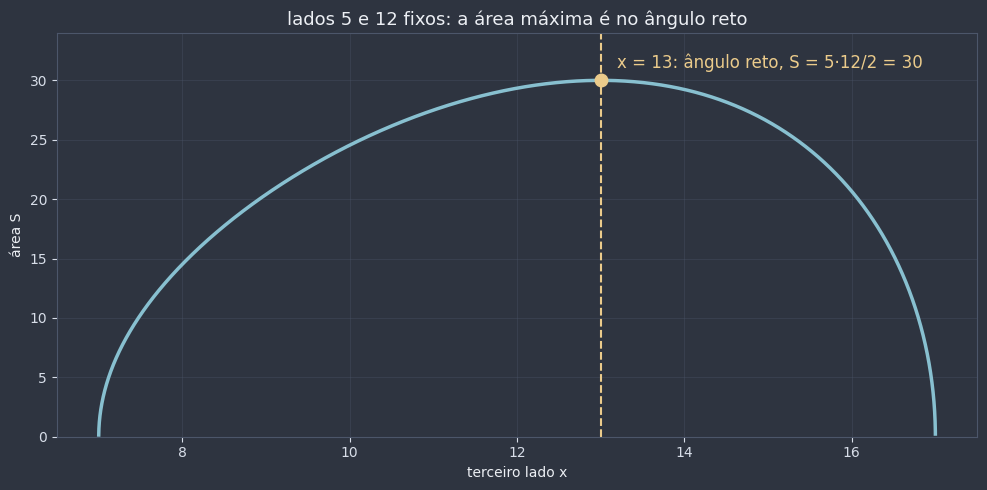

In [11]:
xs_ex10 = np.linspace(7, 17, 100_001)[1:-1]
areas = np.array([area_herao(x, 5, 12) for x in xs_ex10])
indice = int(np.argmax(areas))
x_max_ex10, S_max_ex10 = float(xs_ex10[indice]), float(areas[indice])

A, B, C = triangulo_por_lados(x_max_ex10, 5, 12)
angulo_ex10 = medir_angulo(A, B, C)

print(x_max_ex10, S_max_ex10, angulo_ex10)

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(NORD_FUNDO)
estilizar_eixo(ax)
ax.plot(xs_ex10, areas, color=COR_PONTO, lw=2.5)
ax.axvline(13, color=COR_AVISO, ls="--", lw=1.5)
ax.plot(x_max_ex10, S_max_ex10, "o", color=COR_AVISO, markersize=9)
ax.text(13.2, 31, "x = 13: ângulo reto, S = 5·12/2 = 30", color=COR_AVISO, fontsize=12)
ax.set_xlabel("terceiro lado x", color=NORD_TEXTO)
ax.set_ylabel("área S", color=NORD_TEXTO)
ax.set_ylim(0, 34)
ax.set_title("lados 5 e 12 fixos: a área máxima é no ângulo reto", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

A área máxima, 30, acontece em $x = 13$: o triângulo $5$–$12$–$13$, **retângulo** no ângulo entre os lados fixos. O motivo, sem cálculo: $S = \frac{12 \cdot h}{2}$, em que $h$ é a altura relativa ao lado 12, e $h \leq 5$ (a altura é um cateto do triângulo retângulo cuja hipotenusa é o lado 5). A igualdade $h = 5$ só vale quando o lado 5 é **perpendicular** ao lado 12. É a dobradiça do gancho: abrindo o ângulo, a área cresce até 90° e depois diminui, simétrica em torno do ângulo reto.